In [16]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
%matplotlib inline
print("Libraries imported successfully!")

Libraries imported successfully!


In [17]:
# Tải toàn bộ dữ liệu CSV thô trong mục raw/unified
data_dir = '../data/raw/'
csv_files = glob.glob(os.path.join(data_dir, '*.csv'))

data_dict = {}
print(f"Bắt đầu đọc {len(csv_files)} file CSV...")

for file in csv_files:
    # Lấy tên file gốc (Bỏ path và định dạng .csv) làm Ticker
    ticker = os.path.basename(file).split('.')[0]
    
    # Đọc dữ liệu với cột định dạng Thời gian làm chỉ mục (Index)
    df = pd.read_csv(file, parse_dates=['Date'])
    df.set_index('Date', inplace=True)
    df.sort_index(inplace=True)
    
    data_dict[ticker] = df

print("Hoàn tất! Danh sách các dữ liệu:", list(data_dict.keys()))

Bắt đầu đọc 8 file CSV...
Hoàn tất! Danh sách các dữ liệu: ['FPT', 'HPG', 'SSI', 'VCB', 'VHM', 'VN30', 'VNINDEX', 'VNM']


In [18]:
# Tổng kết chung các tập dữ liệu: Bảng Tóm Tắt (Summary Table)
# LƯU Ý: Chứng khoán có thể có giá giống nhau ở nhiều ngày, 
# nên duplicated() chỉ được tính là lỗi nếu trùng lặp trên cùng 1 Ngày Giao Dịch (Date).
summary_data = []

for ticker, df in data_dict.items():
    summary_data.append({
        'Ticker': ticker,
        'Mẫu (Rows)': len(df),
        'Thuộc tính (Columns)': len(df.columns),
        'Ngày Bắt Đầu': df.index.min().strftime('%Y-%m-%d'),
        'Ngày Kết Thúc': df.index.max().strftime('%Y-%m-%d'),
        'Số năm dữ liệu (~ Năm)': round((df.index.max() - df.index.min()).days / 365.25, 1),
        'Tổng Missing Values': df.isnull().sum().sum(),
        'Trùng Ngày Giao Dịch': df.index.duplicated().sum()
    })

summary_df = pd.DataFrame(summary_data).set_index('Ticker').sort_values(by='Mẫu (Rows)')
display(summary_df)

,Mẫu (Rows),Thuộc tính (Columns),Ngày Bắt Đầu,Ngày Kết Thúc,Số năm dữ liệu (~ Năm),Tổng Missing Values,Trùng Ngày Giao Dịch
Ticker,,,,,,,
VHM,1910,5,2018-05-17,2025-12-31,7.6,0,0
VN30,2088,5,2017-08-24,2025-12-31,8.4,0,0
VNINDEX,2088,5,2017-08-24,2025-12-31,8.4,0,0
FPT,3243,5,2013-01-02,2025-12-31,13.0,0,0
VCB,3243,5,2013-01-02,2025-12-31,13.0,0,0
SSI,3243,5,2013-01-02,2025-12-31,13.0,0,0
HPG,3243,5,2013-01-02,2025-12-31,13.0,0,0
VNM,3243,5,2013-01-02,2025-12-31,13.0,0,0


In [19]:
# Tìm và hiển thị các dòng dữ liệu bị lỗi lặp lại theo NGÀY (Date)
print("Kiểm tra lặp dữ liệu theo biến thời gian (Date):")
has_dup = False
for ticker, df in data_dict.items():
    dup_dates = df[df.index.duplicated(keep=False)]
    if len(dup_dates) > 0:
        has_dup = True
        print(f"Cảnh báo: {ticker} có {len(dup_dates)} dòng bị trùng lặp ngày giao dịch!")
        display(dup_dates)
        # Xử lý: Xóa bỏ dữ liệu lặp lại ngày (giữ lại dòng cuối cùng của ngày đó)
        data_dict[ticker] = df[~df.index.duplicated(keep='last')]
        print(f"Đã xử lý xong cho {ticker}.")

if not has_dup:
    print("Không có mã nào bị trùng lặp ngày giao dịch hợp lệ!")

# Cập nhật và in lại bảng Summary
print("\n--- BẢNG TỔNG KẾT SAU KHI KIỂM TRA (CHỈ TÍNH LỖI TRÙNG NGÀY) ---")
summary_data_updated = []
for ticker, df in data_dict.items():
    summary_data_updated.append({
        'Ticker': ticker,
        'Mẫu (Rows)': len(df),
        'Thuộc tính (Columns)': len(df.columns),
        'Ngày Bắt Đầu': df.index.min().strftime('%Y-%m-%d') if not df.empty else None,
        'Ngày Kết Thúc': df.index.max().strftime('%Y-%m-%d') if not df.empty else None,
        'Tổng Missing Values': df.isnull().sum().sum(),
        'Trùng Ngày Giao Dịch': df.index.duplicated().sum()
    })

summary_df_updated = pd.DataFrame(summary_data_updated).set_index('Ticker').sort_values(by='Mẫu (Rows)')
display(summary_df_updated)

Kiểm tra lặp dữ liệu theo biến thời gian (Date):
Không có mã nào bị trùng lặp ngày giao dịch hợp lệ!

--- BẢNG TỔNG KẾT SAU KHI KIỂM TRA (CHỈ TÍNH LỖI TRÙNG NGÀY) ---


,Mẫu (Rows),Thuộc tính (Columns),Ngày Bắt Đầu,Ngày Kết Thúc,Tổng Missing Values,Trùng Ngày Giao Dịch
Ticker,,,,,,
VHM,1910,5,2018-05-17,2025-12-31,0,0
VN30,2088,5,2017-08-24,2025-12-31,0,0
VNINDEX,2088,5,2017-08-24,2025-12-31,0,0
FPT,3243,5,2013-01-02,2025-12-31,0,0
VCB,3243,5,2013-01-02,2025-12-31,0,0
SSI,3243,5,2013-01-02,2025-12-31,0,0
HPG,3243,5,2013-01-02,2025-12-31,0,0
VNM,3243,5,2013-01-02,2025-12-31,0,0


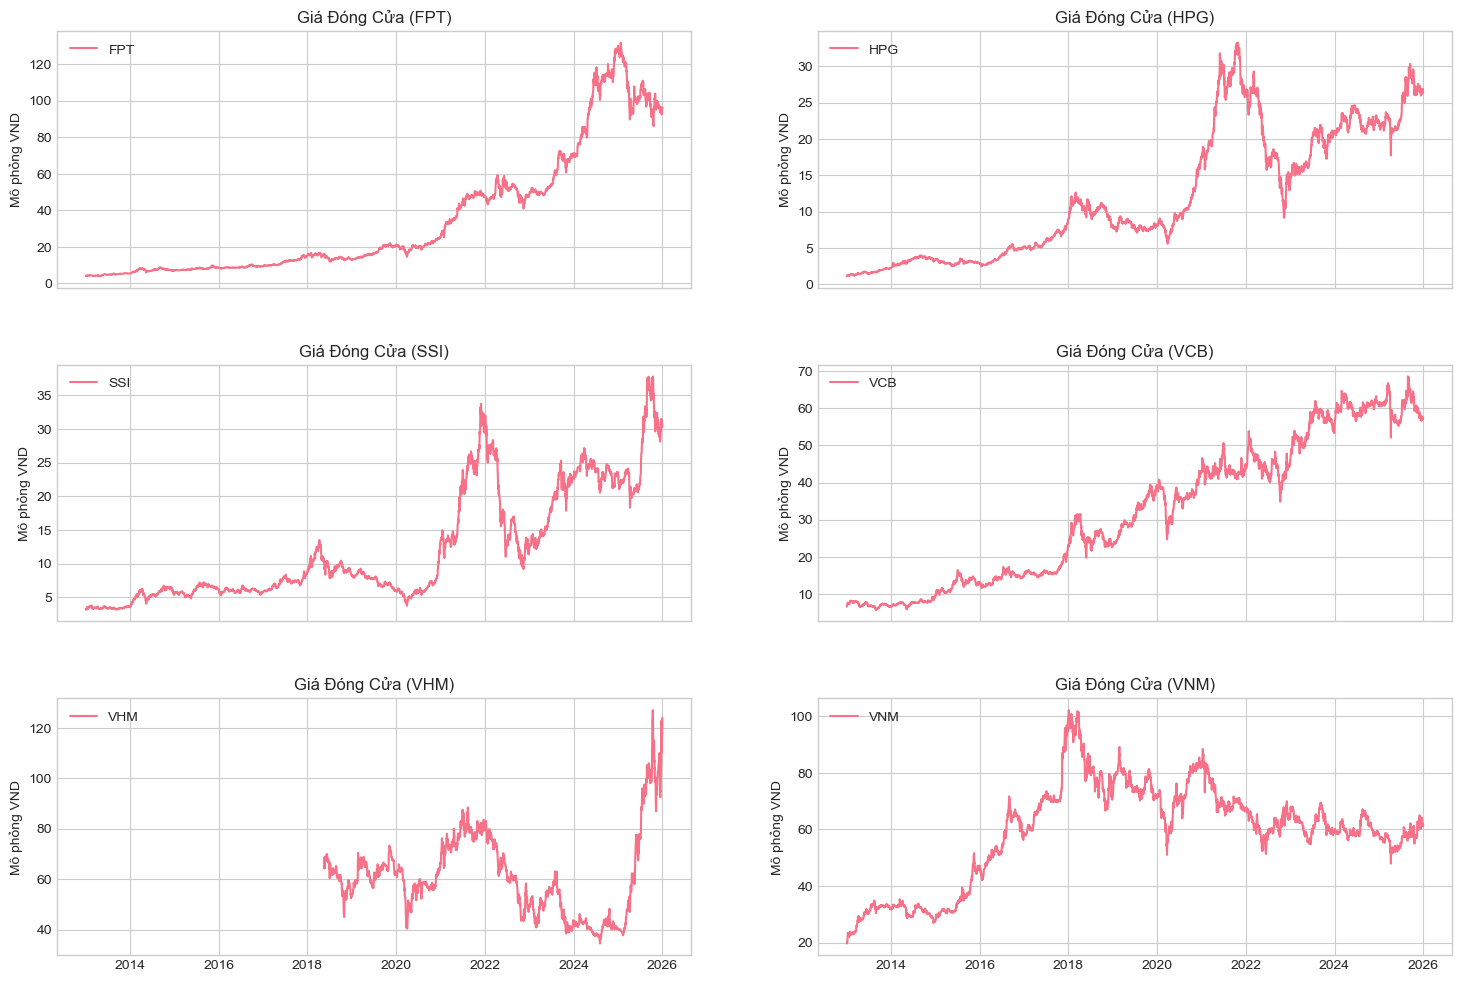

In [20]:
# Trực quan hóa Giá Đóng Cửa (Close Price) của các cổ phiếu riêng lẻ
import matplotlib.dates as mdates

tickers_cophieu = [t for t in data_dict.keys() if t not in ['VNINDEX', 'VN30']]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(18, 12), sharex=True)
fig.subplots_adjust(hspace=0.3)

for ax, ticker in zip(axes.flatten(), tickers_cophieu):
    df_temp = data_dict[ticker]
    ax.plot(df_temp.index, df_temp['Close'], label=ticker, color=sns.color_palette("husl")[0])
    ax.set_title(f'Giá Đóng Cửa ({ticker})')
    ax.set_ylabel('Mô phỏng VND')
    ax.legend(loc='upper left')

# Xử lý các biểu đồ trống nếu số lượng ticker không khớp
for idx in range(len(tickers_cophieu), len(axes.flatten())):
    fig.delaxes(axes.flatten()[idx])
    
plt.show()

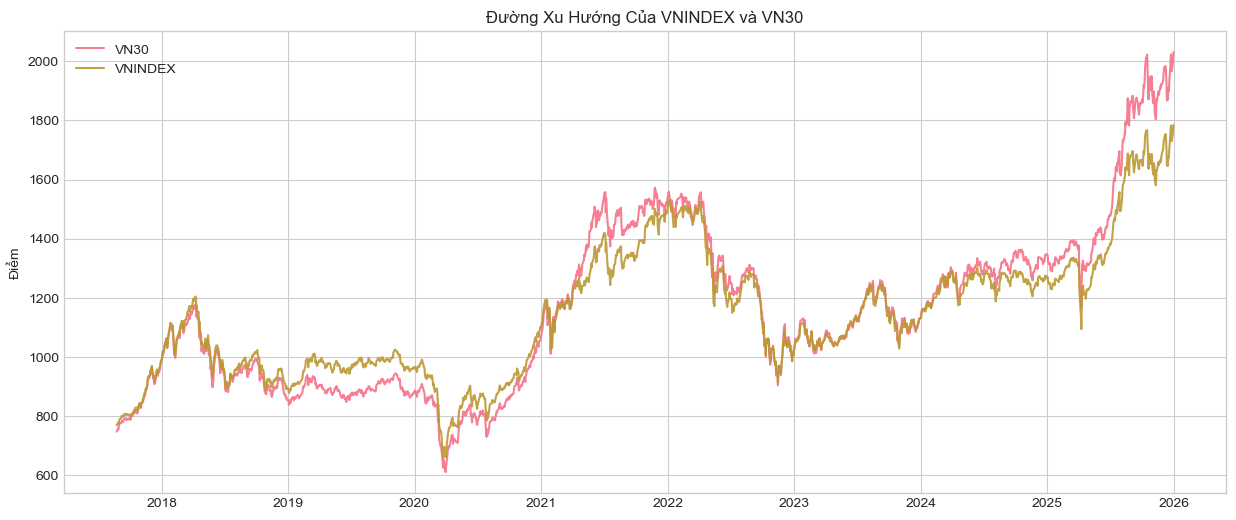

In [7]:
# Trực quan Chỉ Số (Indexes) để so sánh chung
indices = [t for t in data_dict.keys() if t in ['VNINDEX', 'VN30']]

plt.figure(figsize=(15, 6))
for idx in indices:
    plt.plot(data_dict[idx].index, data_dict[idx]['Close'], label=idx, alpha=0.9)
    
plt.title('Đường Xu Hướng Của VNINDEX và VN30')
plt.ylabel('Điểm')
plt.legend()
plt.show()